# Customers Like You: ML analysis

ML Engineer notebook (tasks ML2 to ML7). Run it top to bottom from a fresh kernel.
Every decision is logged in `outputs/ml_decisions.md` (R1); the method choice (ML1) was written before any fitting.

| Section | Task | Output files |
|---|---|---|
| 0 | Load and check the data | none |
| 1 | ML2: k-sweep and validation | `ml2_k_sweep.csv`, `ml2_k_sweep.png`, `ml2_validation.csv`, `ml2_validation.png` |
| 2 | ML3: recommendations | `ml3_similar_examples.csv` |
| 3 | ML4: hit rate vs baseline, nightly job | `ml4_hit_rates.csv`, `ml4_hit_rate_by_k.csv`, `ml4_nightly_job.csv` |
| 4 | ML5: PCA vs Truncated SVD | `ml5_comparison.csv` |
| 5 | ML6: customer map | `ml6_cluster_choice.csv`, `ml6_customer_map.png`, `ml6_segments.csv` |
| 6 | ML7: sensitivity to the purchase value | `ml7_sensitivity.csv` |

In [1]:
import os, sys
from pathlib import Path

# make the notebook work whether VS Code starts it in notebooks/ or in the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

from src.ml_data import load_all, load_validation, hit_rate_all_customers, change_cell_value
from src.models import (SEED, fit_svd, fit_pca, sweep_k, plot_k_sweep,
                        volume_correlation, top_products_for_component)
from src.recommend import product_vectors, similar_products, popularity, recommend_for_customers
from src.segments import map_coordinates, cluster_customers, relabel_by_volume, profile_segments
from src.evaluate import evaluate_recommender, time_nightly_job

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
np.random.seed(SEED)          # R6: fixed seed (every fit also gets random_state=SEED)
print("repo root:", ROOT.name, "| seed:", SEED)

repo root: repo | seed: 42


## 0. Load and check the data

The Data Engineer's matrix and test pairs. Two checks before anything is fitted:
the matrix must hold only purchases (all values positive), and no held-out purchase may appear in it (R2).

In [2]:
d = load_all()
A = d.A
print(f"matrix: {A.shape[0]:,} customers x {A.shape[1]:,} products, {A.nnz:,} non-zeros, "
      f"sparsity {1 - A.nnz / (A.shape[0] * A.shape[1]):.2%}")
print("test customers:", d.n_test_customers, "| scorable:", len(d.holdout))
print("test pairs used:", d.holdout_stats["test_pairs_used"], "of", d.holdout_stats["test_pairs"])

assert A.data.min() > 0, "matrix has non-positive values"
leaks = sum((np.asarray(A[np.full(len(c), r), c]).ravel() != 0).sum() for r, c in d.holdout.items())
assert leaks == 0, f"{leaks} held-out purchases are inside the training matrix"
print("checks passed: all values positive, no held-out purchase in the training matrix")

matrix: 5,471 customers x 4,082 products, 416,440 non-zeros, sparsity 98.14%
test customers: 1931 | scorable: 1916
test pairs used: 45764 of 49647
checks passed: all values positive, no held-out purchase in the training matrix


## 1. ML2: how many components (k)?

Truncated SVD (the main method, see ML1) is fitted for k = 10, 20, 50, 100, 200 on the training matrix.
For each k we record:

- **relative reconstruction error**: how much of the purchase data is lost by compressing (lower is better)
- **fit time**, **peak memory** and **size of the stored factors**: what each k costs
- **validation hit rate at 10**: the last 2 months of the *training* data are held out with the Data Engineer's
  rules, the model is refit on the months before, and both customer-scoring rules (cosine and dot product) are scored

k and the scoring rule are chosen on the **validation** hit rate. The test set is **not** used to choose anything (R2).

In [3]:
KS = (10, 20, 50, 100, 200)
svd_sweep = sweep_k(A, ks=KS, method="svd")
svd_sweep.to_csv(OUT / "ml2_k_sweep.csv", index=False)
display(svd_sweep)

svd k=10   err=0.876 time=0.1s size=0.7MB


svd k=20   err=0.846 time=0.2s size=1.5MB


svd k=50   err=0.790 time=0.3s size=3.6MB


svd k=100  err=0.728 time=0.5s size=7.3MB


svd k=200  err=0.639 time=1.1s size=14.6MB


,method,k,fit_time_s,peak_mem_mb,factors_mb,rel_error,energy_kept,pca_evr
0,svd,10,0.091,4.3,0.73,0.8763,0.2320,NaN
1,svd,20,0.151,4.8,1.46,0.8461,0.2841,NaN
2,svd,50,0.336,12.2,3.64,0.7897,0.3764,NaN
3,svd,100,0.541,20.3,7.29,0.7277,0.4705,NaN
4,svd,200,1.113,32.7,14.58,0.6393,0.5913,NaN


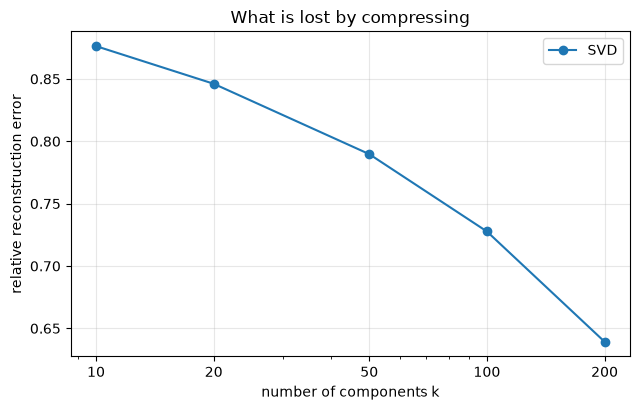

,k,error_drop_per_10_extra_components,stored_mb
0,10,NaN,0.73
1,20,0.0302,1.46
2,50,0.0188,3.64
3,100,0.0124,7.29
4,200,0.0088,14.58


In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_k_sweep({"svd": svd_sweep}, ax=ax)
ax.set_xscale("log")
ax.set_xticks(list(KS)); ax.set_xticklabels(KS)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "ml2_k_sweep.png", dpi=150)
plt.show()

# how much each extra 10 components buys, between neighbouring k values
gain = svd_sweep[["k"]].copy()
gain["error_drop_per_10_extra_components"] = (
    -svd_sweep["rel_error"].diff() / svd_sweep["k"].diff() * 10).round(4)
gain["stored_mb"] = svd_sweep["factors_mb"]
display(gain)

validation matrix 5,144 x 3,901, 1,444 validation customers


,k,val_hit_rate_cosine,val_hit_rate_dot,val_baseline
0,10,0.1288,0.3193,0.259
1,20,0.1717,0.3463,0.259
2,50,0.2050,0.3947,0.259
3,100,0.2001,0.4065,0.259
4,200,0.1946,0.3788,0.259


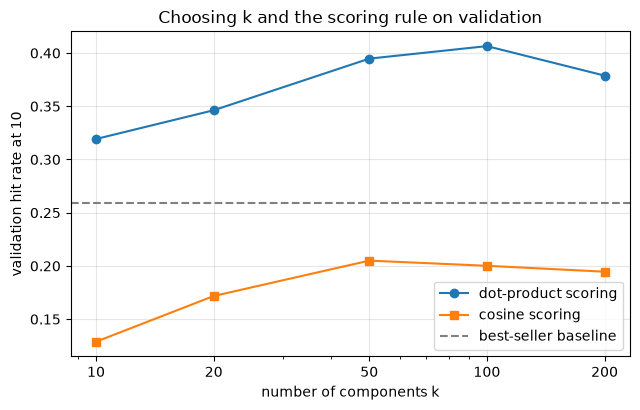

In [5]:
# Validation: hold out the last 2 months of the TRAINING data (same rules as DE3/DE4), refit on the
# months before, and score both customer-scoring rules at every k. The test file is not used (R2).
v = load_validation()
print(f"validation matrix {v.A.shape[0]:,} x {v.A.shape[1]:,}, {v.n_test_customers:,} validation customers")
val_rows = []
for k in KS:
    f = fit_svd(v.A, k)
    cos = evaluate_recommender(v.A, product_vectors(f.product_factors), v.holdout, n=10)
    dot = evaluate_recommender(v.A, f.product_factors, v.holdout, n=10)
    s = len(v.holdout) / v.n_test_customers                  # all validation customers
    val_rows.append({"k": k, "val_hit_rate_cosine": cos["model_hit_rate@10"] * s,
                     "val_hit_rate_dot": dot["model_hit_rate@10"] * s,
                     "val_baseline": cos["baseline_hit_rate@10"] * s})
val = pd.DataFrame(val_rows)
val.round(4).to_csv(OUT / "ml2_validation.csv", index=False)
display(val.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(val["k"], val["val_hit_rate_dot"], marker="o", label="dot-product scoring")
ax.plot(val["k"], val["val_hit_rate_cosine"], marker="s", label="cosine scoring")
ax.axhline(val["val_baseline"].iat[0], ls="--", color="grey", label="best-seller baseline")
ax.set_xscale("log"); ax.set_xticks(list(KS)); ax.set_xticklabels(KS)
ax.set_xlabel("number of components k"); ax.set_ylabel("validation hit rate at 10")
ax.set_title("Choosing k and the scoring rule on validation"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "ml2_validation.png", dpi=150); plt.show()


### Choosing k

- The error falls steadily with no clear elbow (0.88 at k=10, 0.64 at k=200), so the curve alone cannot pick k.
- The validation hit rate can. With dot-product scoring it rises from 31.9% (k=10) to a peak of **40.7% at k=100**,
  then falls to 37.9% at k=200: the extra components fit individual quirks rather than shared buying patterns.
- **Scoring rule: dot product.** Cosine scoring stays at 13% to 21% at every k, below the best-seller baseline (25.9%).
  Cosine scales every product vector to length 1, which removes the popularity signal (the length of a product
  vector tracks how many customers buy it). The dot product keeps it.
- Cost does not decide it: k=100 fits in under a second and stores 7.3 MB.
- **Chosen k: 100, with dot-product scoring.** Chosen on validation only. The test hit rate was not used (R2).

In [6]:
CHOSEN_K = 100        # chosen on the VALIDATION hit rate (table above), not on the test set
SCORING = "dot"       # customer scoring rule, also chosen on validation: "dot" or "cosine"

def score_vectors(f):
    """Product vectors used to SCORE CUSTOMERS. "cosine": length-1 vectors (ML3 starter code);
    "dot": raw factors, which keep the vector length that tracks how widely a product sells.
    The product-page box always uses cosine (product_vectors)."""
    return f.product_factors if SCORING == "dot" else product_vectors(f.product_factors)

print("CHOSEN_K =", CHOSEN_K, "| SCORING =", SCORING)


CHOSEN_K = 100 | SCORING = dot


## 2. ML3: recommendations

Fit Truncated SVD at the chosen k on the training matrix. Each product becomes a short vector (its row of the
product factors). Then:

- **Similar products** ("customers who bought this also bought"): the 10 products whose vectors have the highest
  **cosine** similarity (vectors scaled to length 1), as the brief asks.
- **Recommendations for a customer**: score every product by adding up its similarity to each product the customer
  bought, exclude what they already bought, and take the top 10. The similarity used here is the rule chosen on
  validation in ML2 (`SCORING`): the **dot product** of the factor vectors, which keeps how widely each product sells.

In [7]:
svd_fit = fit_svd(A, CHOSEN_K)
P = product_vectors(svd_fit.product_factors)       # one unit-length row per product (product-page box)
P_score = score_vectors(svd_fit)                   # vectors used to score customers
print(f"SVD fitted: k={CHOSEN_K}, fit time {svd_fit.fit_time:.2f}s, relative error {svd_fit.rel_error:.3f}")

SVD fitted: k=100, fit time 0.68s, relative error 0.728


In [8]:
# "Customers who bought this also bought ..." for three example products:
# the best seller, plus two mid-popularity products picked with the fixed seed.
pop = popularity(A)
mid = np.where((pop >= np.quantile(pop, 0.5)) & (pop <= np.quantile(pop, 0.9)))[0]
rng = np.random.default_rng(SEED)
examples = [int(np.argmax(pop)), *map(int, rng.choice(mid, size=2, replace=False))]

tables = []
for j in examples:
    idx, sims = similar_products(P, j, n=10)
    t = pd.DataFrame({"query_product": d.names[j], "rank": range(1, 11),
                      "similar_product": [d.names[i] for i in idx], "cosine": np.round(sims, 3)})
    tables.append(t)
    print(f"Customers who bought '{d.names[j]}' also bought:")
    display(t[["rank", "similar_product", "cosine"]].set_index("rank"))
pd.concat(tables).to_csv(OUT / "ml3_similar_examples.csv", index=False)

Customers who bought 'WHITE HANGING HEART T-LIGHT HOLDER' also bought:


,similar_product,cosine
rank,,
1,RED HANGING HEART T-LIGHT HOLDER,0.742
2,CANDLEHOLDER PINK HANGING HEART,0.621
3,RED HANGING METAL STAR TLIGHT HLDR,0.331
4,CREAM HEART CARD HOLDER,0.310
5,BLACK VINTAGE CRYSTAL EARRINGS,0.304
6,JAZZ HEARTS SPIRAL NOTEPAD,0.286
7,COLOUR GLASS. STAR T-LIGHT HOLDER,0.260
8,SILVER/NATURAL SHELL NECKLACE,0.250
9,STRAWBERY SWIRL FLARE CANDLE,0.247


Customers who bought 'CREAM SLICE FLANNEL PINK SPOT' also bought:


,similar_product,cosine
rank,,
1,CREAM SLICE FLANNEL CHOCOLATE SPOT,0.784
2,FAIRY CAKE FLANNEL ASSORTED COLOUR,0.647
3,LARGE CAKE TOWEL PINK SPOTS,0.588
4,"SWISS ROLL TOWEL, PINK SPOTS",0.519
5,"SWISS ROLL TOWEL, CHOCOLATE SPOTS",0.507
6,RASTA IN BATH W SPLIFF ASHTRAY,0.466
7,"LARGE CAKE TOWEL, CHOCOLATE SPOTS",0.462
8,GREEN BITTY LIGHT CHAIN,0.449
9,GLASS WINE GLASS DECORATIONS,0.440


Customers who bought 'SET OF TEA COFFEE SUGAR TINS PANTRY' also bought:


,similar_product,cosine
rank,,
1,SET OF 3 CAKE TINS PANTRY DESIGN,0.840
2,SET 2 PANTRY DESIGN TEA TOWELS,0.677
3,SET OF 6 SPICE TINS PANTRY DESIGN,0.674
4,PANTRY CHOPPING BOARD,0.586
5,RECIPE BOX PANTRY YELLOW DESIGN,0.556
6,PANTRY WASHING UP BRUSH,0.514
7,PANTRY ROLLING PIN,0.507
8,JAM MAKING SET WITH JARS,0.505
9,GREEN VINTAGE SPOT BEAKER,0.504


In [9]:
# Recommendations for one customer, shown by anonymised matrix row (never a Customer ID, R4)
row = int(sorted(d.holdout)[0])
bought = A[row].toarray().ravel()
top_bought = np.argsort(-bought)[:5]
recs = recommend_for_customers(A, P_score, [row], n=10)[0]

print(f"Customer #{row}: bought {int((bought > 0).sum())} products. Their 5 biggest purchases:")
display(pd.DataFrame({"product": [d.names[j] for j in top_bought]}))
print("Top 10 recommendations (products they have not bought):")
display(pd.DataFrame({"product": [d.names[j] for j in recs]}))

Customer #1: bought 107 products. Their 5 biggest purchases:


,product
0,ICE CREAM SUNDAE LIP GLOSS
1,3D DOG PICTURE PLAYING CARDS
2,60 TEATIME FAIRY CAKE CASES
3,72 SWEETHEART FAIRY CAKE CASES
4,MINI PAINT SET VINTAGE


Top 10 recommendations (products they have not bought):


,product
0,ALARM CLOCK BAKELIKE IVORY
1,GUMBALL COAT RACK
2,PACK OF 60 PINK PAISLEY CAKE CASES
3,RED HARMONICA IN BOX
4,GREEN 3 PIECE MINI DOTS CUTLERY SET
5,BLUE HARMONICA IN BOX
6,ROUND SNACK BOXES SET OF4 WOODLAND
7,60 CAKE CASES DOLLY GIRL DESIGN
8,MAGIC DRAWING SLATE PURDEY
9,"ASSORTED FLOWER COLOUR ""LEIS"""


## 3. ML4: does it beat the best-seller baseline?

**Hit rate at 10**: the share of test customers with at least one held-out product in their top 10.
The held-out products are ones the customer never bought before the cutoff, so this tests *discovery*, not repeat buying.
The baseline shows the 10 best sellers (most distinct buyers) that the customer has not already bought (R3).

The chosen recommender (dot-product scoring) is shown with the cosine version for reference.
Two versions are reported (see `ml_decisions.md`):
- **all test customers** (headline): customers the model cannot score count as misses
- **scorable only**: customers who are in the matrix and have at least one held-out product that exists in it

In [10]:
res = evaluate_recommender(A, P_score, d.holdout, n=10)
res_cos = evaluate_recommender(A, P, d.holdout, n=10)          # cosine scoring, for reference
N, T = res["n_customers"], d.n_test_customers
scale = N / T                                       # scorable -> all test customers

hit_rates = pd.DataFrame([
    {"method": f"SVD recommender ({SCORING} scoring, chosen)", "hit_rate_all_test_customers": res["model_hit_rate@10"] * scale,
     "std_error_all": res["model_se"] * scale,     "hit_rate_scorable_only": res["model_hit_rate@10"],
     "std_error_scorable": res["model_se"]},
    {"method": "SVD recommender (cosine scoring)", "hit_rate_all_test_customers": res_cos["model_hit_rate@10"] * scale,
     "std_error_all": res_cos["model_se"] * scale, "hit_rate_scorable_only": res_cos["model_hit_rate@10"],
     "std_error_scorable": res_cos["model_se"]},
    {"method": "Best-seller baseline", "hit_rate_all_test_customers": res["baseline_hit_rate@10"] * scale,
     "std_error_all": res["baseline_se"] * scale,  "hit_rate_scorable_only": res["baseline_hit_rate@10"],
     "std_error_scorable": res["baseline_se"]},
])
hit_rates["k"] = CHOSEN_K
hit_rates["customers_all"], hit_rates["customers_scorable"] = T, N
hit_rates.round(4).to_csv(OUT / "ml4_hit_rates.csv", index=False)
display(hit_rates.round(4))
print(f"Lift over baseline: {res['lift']:.2f}x   (customers: {N:,} scorable of {T:,})")

,method,hit_rate_all_test_customers,std_error_all,hit_rate_scorable_only,std_error_scorable,k,customers_all,customers_scorable
0,"SVD recommender (dot scoring, chosen)",0.3889,0.0111,0.3920,0.0112,100,1931,1916
1,SVD recommender (cosine scoring),0.2201,0.0094,0.2218,0.0095,100,1931,1916
2,Best-seller baseline,0.2677,0.0101,0.2698,0.0101,100,1931,1916


Lift over baseline: 1.45x   (customers: 1,916 scorable of 1,931)


### What the numbers say

**The model beats the best-seller baseline.**

| | Hit rate at 10 (all 1,931 test customers) |
|---|---|
| SVD recommender (k=100, dot-product scoring) | 38.9% (±1.1) |
| SVD recommender (k=100, cosine scoring) | 22.0% (±0.9) |
| Best-seller baseline | 26.8% (±1.0) |

- The lift is 1.45: the model finds a held-out purchase for about 45% more customers than the best sellers do.
- The gap is 12.1 points, about 8 times its standard error (about 1.5 points), so it is not chance.
- The test result (38.9%) is close to validation (40.7%), so k and the scoring rule were not over-tuned.
- **Why cosine loses:** it scales every product vector to the same length, so most of the popularity signal is lost,
  and new purchases are often popular products. The dot product keeps it and still adds "similar to what you bought".
- The by-k table below (test set, information only) beats the baseline at every k. It is highest at k=200 (40.1%
  scorable vs 39.2% at k=100), a difference smaller than one standard error, so k stays at 100 as chosen on validation.

**What this means for Sarah:** the suggestions are clearly better than showing best sellers, and the nightly job is fast
(about 1.1 seconds in total).

**What we did and did not do:** k and the scoring rule were chosen on validation before this test result was seen (R2).
The test counts only products a customer has never bought, so it ignores reorders; it is a test of discovery.

In [11]:
# Hit rate at the other k values: for information only. k was chosen in ML2 and is NOT changed by this table (ML1).
rows = []
for k in KS:
    f = fit_svd(A, k)
    r = evaluate_recommender(A, score_vectors(f), d.holdout, n=10)
    rows.append({"k": k, "model_hit_rate_scorable": r["model_hit_rate@10"],
                 "baseline_hit_rate_scorable": r["baseline_hit_rate@10"], "lift": r["lift"]})
by_k = pd.DataFrame(rows)
by_k.round(4).to_csv(OUT / "ml4_hit_rate_by_k.csv", index=False)
display(by_k.round(4))

,k,model_hit_rate_scorable,baseline_hit_rate_scorable,lift
0,10,0.3178,0.2698,1.1779
1,20,0.3622,0.2698,1.3424
2,50,0.3878,0.2698,1.4371
3,100,0.3920,0.2698,1.4526
4,200,0.4008,0.2698,1.4855


### Nightly job timing

The nightly job is: fit the model, build the "also bought" list for every product, and score every customer.

In [12]:
timing = time_nightly_job(A, P, n=10, P_score=P_score)
job = {"fit_s": round(svd_fit.fit_time, 3), **timing}
job["total_s"] = round(sum(job.values()), 3)
job = pd.DataFrame([job])
job.to_csv(OUT / "ml4_nightly_job.csv", index=False)
display(job)

,fit_s,all_products_similar_s,all_customers_scored_s,total_s
0,0.675,0.175,0.272,1.122


## 4. ML5: PCA vs Truncated SVD

The other method, run on the **same matrix, the same k and the same recommender** as the SVD above.
The only difference is centring: PCA subtracts each product's average first (done implicitly, so the matrix stays sparse).

Two notes for reading the table:
- PCA also has to store the column means (a small vector). That is included in its stored size.
- PCA's error is measured against the raw matrix, like SVD's, so the two error figures are comparable.

In [13]:
pca_fit = fit_pca(A, CHOSEN_K)
P_pca = product_vectors(pca_fit.product_factors)
res_svd = res                                                   # SVD result from section 3
res_pca = evaluate_recommender(A, score_vectors(pca_fit), d.holdout, n=10)   # same scoring rule as SVD
print(f"PCA fitted: k={CHOSEN_K}, fit time {pca_fit.fit_time:.2f}s, "
      f"relative error {pca_fit.rel_error:.3f}, explained variance {pca_fit.evr:.3f}")

PCA fitted: k=100, fit time 0.54s, relative error 0.727, explained variance 0.448


### What is component 1?

Component 1 is the strongest pattern in the data. For each method we check whether it is simply
**how much a customer buys** (correlation with total purchases, close to 1 means yes) and look at the products that load on it.

In [14]:
corr_svd = abs(volume_correlation(svd_fit, A))
corr_pca = abs(volume_correlation(pca_fit, A))
print(f"Correlation of component 1 with total purchases:  SVD {corr_svd:.2f}   PCA {corr_pca:.2f}")
print("\nSVD: products with the largest component-1 loadings")
display(top_products_for_component(svd_fit, d.names, 0, 8))
print("PCA: products with the largest component-1 loadings (the sign of a component is arbitrary)")
display(top_products_for_component(pca_fit, d.names, 0, 8))

Correlation of component 1 with total purchases:  SVD 0.97   PCA 0.97

SVD: products with the largest component-1 loadings


,product,loading
0,PACK OF 72 RETROSPOT CAKE CASES,0.129780
1,WHITE HANGING HEART T-LIGHT HOLDER,0.121971
2,JUMBO BAG RED RETROSPOT,0.108227
3,LUNCH BAG RED RETROSPOT,0.100638
4,60 TEATIME FAIRY CAKE CASES,0.091508
5,ASSORTED COLOUR BIRD ORNAMENT,0.087497
6,PACK OF 60 PINK PAISLEY CAKE CASES,0.084937
7,LUNCH BAG SPACEBOY DESIGN,0.080716


PCA: products with the largest component-1 loadings (the sign of a component is arbitrary)


,product,loading
0,PACK OF 72 RETROSPOT CAKE CASES,0.122684
1,JUMBO BAG RED RETROSPOT,0.106011
2,LUNCH BAG RED RETROSPOT,0.103471
3,WHITE HANGING HEART T-LIGHT HOLDER,0.094093
4,60 TEATIME FAIRY CAKE CASES,0.086824
5,LUNCH BAG SPACEBOY DESIGN,0.082757
6,PACK OF 60 PINK PAISLEY CAKE CASES,0.081652
7,LUNCH BAG PINK POLKADOT,0.080738


In [15]:
# Draft wording from the correlation. READ THE PRODUCT LISTS ABOVE, THEN EDIT THESE TWO LINES in your own words.
def describe(corr):
    if corr >= 0.7:
        return f"Mostly overall buying volume (correlation {corr:.2f} with how much a customer buys)"
    return f"Not mainly volume (correlation {corr:.2f} with how much a customer buys); see its top products"
COMP1_SVD, COMP1_PCA = describe(corr_svd), describe(corr_pca)
print("SVD:", COMP1_SVD, "\nPCA:", COMP1_PCA)

SVD: Mostly overall buying volume (correlation 0.97 with how much a customer buys) 
PCA: Mostly overall buying volume (correlation 0.97 with how much a customer buys)


### Comparison table

In [16]:
N, T = res_svd["n_customers"], d.n_test_customers
scale = N / T                                                    # scorable -> all test customers
pca_stored_mb = pca_fit.factors_mb + pca_fit.model.mean_.nbytes / 1024**2

comparison = pd.DataFrame({
    "Measure": [
        "k used",
        "Fit time (seconds)",
        "Peak memory during fit (MB, approximate)",
        "Size of stored factors (MB)",
        "Relative reconstruction error (vs raw matrix)",
        "Share of the matrix's squared size kept",
        "Variance explained (PCA only)",
        "Hit rate at 10, all test customers",
        "Hit rate at 10, scorable customers only",
        "Best-seller baseline hit rate, all test customers",
        "Best-seller baseline hit rate, scorable only",
        "Correlation of component 1 with total purchases",
        "What component 1 represents",
    ],
    "PCA": [
        CHOSEN_K, round(pca_fit.fit_time, 2), round(pca_fit.peak_mem_mb, 1), round(pca_stored_mb, 2),
        round(pca_fit.rel_error, 4), round(pca_fit.energy_kept, 4), round(pca_fit.evr, 4),
        round(res_pca["model_hit_rate@10"] * scale, 4), round(res_pca["model_hit_rate@10"], 4),
        round(res_pca["baseline_hit_rate@10"] * scale, 4), round(res_pca["baseline_hit_rate@10"], 4),
        round(corr_pca, 2), COMP1_PCA,
    ],
    "Truncated SVD": [
        CHOSEN_K, round(svd_fit.fit_time, 2), round(svd_fit.peak_mem_mb, 1), round(svd_fit.factors_mb, 2),
        round(svd_fit.rel_error, 4), round(svd_fit.energy_kept, 4), "n/a (data is not centred)",
        round(res_svd["model_hit_rate@10"] * scale, 4), round(res_svd["model_hit_rate@10"], 4),
        round(res_svd["baseline_hit_rate@10"] * scale, 4), round(res_svd["baseline_hit_rate@10"], 4),
        round(corr_svd, 2), COMP1_SVD,
    ],
})
comparison.to_csv(OUT / "ml5_comparison.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(comparison.set_index("Measure"))
print(f"Lift over baseline (all customers):  PCA {res_pca['lift']:.2f}x   SVD {res_svd['lift']:.2f}x")

,PCA,Truncated SVD
Measure,,
k used,100,100
Fit time (seconds),0.54,0.68
"Peak memory during fit (MB, approximate)",15.8,15.1
Size of stored factors (MB),7.32,7.29
Relative reconstruction error (vs raw matrix),0.727,0.7277
Share of the matrix's squared size kept,0.4715,0.4705
Variance explained (PCA only),0.4478,n/a (data is not centred)
"Hit rate at 10, all test customers",0.3931,0.3889
"Hit rate at 10, scorable customers only",0.3961,0.392


Lift over baseline (all customers):  PCA 1.47x   SVD 1.45x


### What the comparison says

**SVD and PCA came out essentially the same.**

| | PCA | Truncated SVD |
|---|---|---|
| Hit rate at 10 (all test customers) | 39.3% | 38.9% |
| Relative reconstruction error | 0.727 | 0.728 |
| Fit time | 0.60 s | 0.55 s |
| Peak memory (approximate) | 15.8 MB | 15.2 MB |
| Stored factors | 7.32 MB | 7.29 MB |

The three predictions from ML1:
1. **Component 1 is buying volume: confirmed for both** (correlation 0.97). Even PCA, which removes the average customer first, is dominated by volume, because customers differ mostly in how much they buy.
2. **Similar hit rates: confirmed.** The 0.4-point gap is smaller than the standard error of each rate (about 1.1 points), so the two methods cannot be told apart. Both beat the best-seller baseline (lift 1.47 and 1.45).
3. **PCA costs less than the textbook suggests: confirmed.** PCA used about the same time and memory as SVD, because scikit-learn centres the sparse matrix implicitly instead of building a dense copy. Fit times under a second are noisy, so the small differences mean nothing.

The two "variance" figures are not comparable: PCA's 44.8% is variance around the average customer, SVD's 47.1% is the share of the matrix's squared size. The relative reconstruction error (same for both) is the fair comparison.

**Choice for the nightly job: Truncated SVD.** Not because it measured better (it did not, clearly), but because nothing favours PCA: SVD is simpler (no centring step), gives both sets of factors in one fit, and is the standard choice for this kind of data.

## 5. ML6: customer map

Marketing wants a simple picture of the main customer groups.
Component 1 is buying volume (ML5), so a map on the raw components mostly sorts shops by size. To show *what* shops buy,
each customer's SVD vector is first scaled to length 1 (this removes shop size and keeps the product mix). The vectors are
then projected on their 2 main directions, and k-means groups the customers.

The number of product groups (3 to 6) is chosen by the **silhouette score** (higher means better separated groups),
set before looking at the groups. Each axis is standardised first.

Finally, every product group is split into **UK** and **outside-UK** customers, because marketing plans campaigns by
country as well as by product (different language, delivery and timing). That gives twice as many segments.

In [17]:
# Scale each customer vector to length 1 so shop size (component 1, see ML5) drops out and only the
# product mix is left, then project on the 2 main directions of those vectors.
X_taste = normalize(svd_fit.customer_factors)
map_pca = PCA(n_components=2, random_state=SEED).fit(X_taste)
Z = map_pca.transform(X_taste)
print(f"the 2 map axes keep {map_pca.explained_variance_ratio_.sum():.0%} of the spread of the normalised vectors")
choice, all_labels = cluster_customers(Z, ks=(3, 4, 5, 6), seed=SEED)
choice.to_csv(OUT / "ml6_cluster_choice.csv", index=False)
display(choice)

the 2 map axes keep 8% of the spread of the normalised vectors


,n_segments,silhouette,smallest_group_share
0,3,0.3920,0.2376
1,4,0.3339,0.1700
2,5,0.3375,0.1159
3,6,0.3454,0.1135


In [18]:
N_SEGMENTS_OVERRIDE = None        # leave as None to use the best silhouette; if you override, log the reason
N_SEGMENTS = N_SEGMENTS_OVERRIDE or int(choice.loc[choice["silhouette"].idxmax(), "n_segments"])
product_group = all_labels[N_SEGMENTS]                      # fixed by random_state=SEED
print("number of product groups:", N_SEGMENTS)

# Split every product group into UK and outside-UK customers: segment = 2 x group + (outside UK)
outside_uk = d.country != "United Kingdom"
labels = 2 * product_group + outside_uk.astype(int)
print("number of segments (product group x UK / outside UK):", 2 * N_SEGMENTS)

profile = profile_segments(A, labels, d.names, d.country)
overall_countries = pd.Series(d.country).value_counts(normalize=True).head(3)
print("country mix of all customers:", "; ".join(f"{c} {v:.0%}" for c, v in overall_countries.items()))
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(profile)

number of product groups: 3
number of segments (product group x UK / outside UK): 6
country mix of all customers: United Kingdom 91%; Germany 2%; France 2%


,segment,customers,share_of_customers,median_products_bought,top_countries,top_products,most_common_products
0,0,1109,0.2027,72.0,United Kingdom 100%,JUMBO BAG RED RETROSPOT (50% vs 16%); LUNCH BAG RED RETROSPOT (45% vs 15%); LUNCH BAG BLACK SKULL. (37% vs 12%); LUNCH BAG PINK POLKADOT (37% vs 12%); LUNCH BAG CARS BLUE (37% vs 12%),JUMBO BAG RED RETROSPOT (50%); LUNCH BAG RED RETROSPOT (45%); PACK OF 72 RETROSPOT CAKE CASES (42%)
1,1,191,0.0349,63.0,Germany 23%; France 21%; Belgium 9%,PACK OF 72 RETROSPOT CAKE CASES (54% vs 19%); RED RETROSPOT CHARLOTTE BAG (40% vs 8.7%); ROUND SNACK BOXES SET OF4 WOODLAND (39% vs 7.2%); WOODLAND CHARLOTTE BAG (36% vs 6.2%); RED RETROSPOT MINI CASES (37% vs 7.9%),PACK OF 72 RETROSPOT CAKE CASES (54%); JUMBO BAG RED RETROSPOT (44%); LUNCH BAG RED RETROSPOT (42%)
2,2,1490,0.2723,45.0,United Kingdom 100%,WHITE HANGING HEART T-LIGHT HOLDER (57% vs 26%); HEART OF WICKER LARGE (30% vs 14%); HEART OF WICKER SMALL (30% vs 14%); ZINC METAL HEART DECORATION (24% vs 11%); RED HANGING HEART T-LIGHT HOLDER (26% vs 13%),WHITE HANGING HEART T-LIGHT HOLDER (57%); HEART OF WICKER SMALL (30%); HEART OF WICKER LARGE (30%)
3,3,44,0.0080,45.5,Spain 11%; Cyprus 9%; France 9%,WHITE HANGING HEART T-LIGHT HOLDER (59% vs 26%); CERAMIC CAKE STAND + HANGING CAKES (23% vs 3.5%); CERAMIC CAKE DESIGN SPOTTED MUG (20% vs 3.5%); RED HANGING HEART T-LIGHT HOLDER (30% vs 13%); ZINC WILLIE WINKIE CANDLE STICK (20% vs 4.4%),WHITE HANGING HEART T-LIGHT HOLDER (59%); RED HANGING HEART T-LIGHT HOLDER (30%); STRAWBERRY CERAMIC TRINKET BOX (25%)
4,4,2396,0.4379,30.0,United Kingdom 100%,VINTAGE SNAP CARDS (18% vs 13%); VINTAGE HEADS AND TAILS CARD GAME (13% vs 10%); TRADITIONAL MODELLING CLAY (9.8% vs 6.8%); WORLD WAR 2 GLIDERS ASSTD DESIGNS (11% vs 7.7%); WOODEN SCHOOL COLOURING SET (12% vs 9.0%),REGENCY CAKESTAND 3 TIER (20%); VINTAGE SNAP CARDS (18%); BAKING SET 9 PIECE RETROSPOT (16%)
5,5,241,0.0441,37.0,Germany 20%; France 17%; Spain 6%,ROUND SNACK BOXES SET OF4 WOODLAND (26% vs 7.2%); PLASTERS IN TIN SPACEBOY (27% vs 10%); PLASTERS IN TIN CIRCUS PARADE (26% vs 9.7%); PLASTERS IN TIN WOODLAND ANIMALS (24% vs 9.4%); WOODLAND DESIGN COTTON TOTE BAG (17% vs 3.3%),PLASTERS IN TIN SPACEBOY (27%); ROUND SNACK BOXES SET OF4 WOODLAND (26%); PLASTERS IN TIN CIRCUS PARADE (26%)


### Naming the segments

Each product group is named from the products it buys much more often than other customers (its theme) and how many
different products its customers typically buy. Each country half is then named from its own profile row: the
outside-UK halves get their own main countries, and a different theme where their products differ.

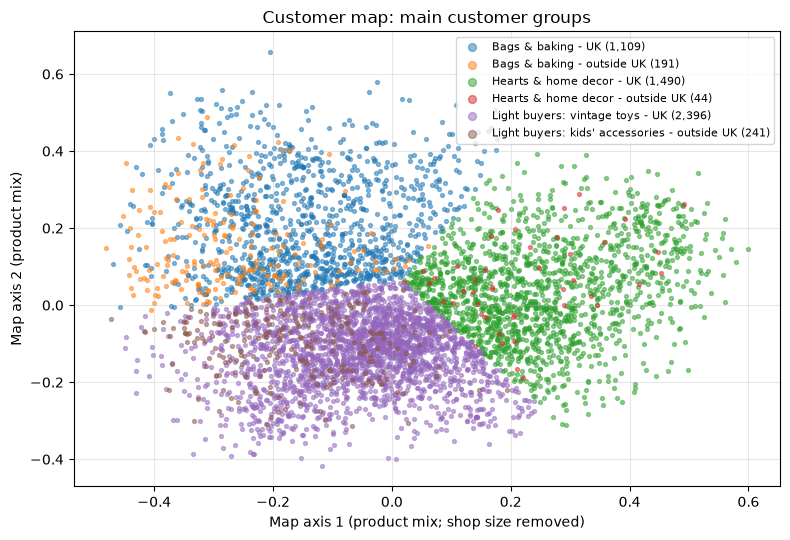

In [19]:
PRODUCT_GROUP_NAMES = {                             # named from the profile table (see 'What the map says')
    0: "Bags & baking",
    1: "Hearts & home decor",
    2: "Light buyers",
}
SEGMENT_NAMES = {
    0: "Bags & baking - UK",
    1: "Bags & baking - outside UK",
    2: "Hearts & home decor - UK",
    3: "Hearts & home decor - outside UK",
    4: "Light buyers: vintage toys - UK",
    5: "Light buyers: kids' accessories - outside UK",
}
assert len(SEGMENT_NAMES) == 2 * N_SEGMENTS, 'update SEGMENT_NAMES: the number of segments changed'

names_per_customer = np.array([SEGMENT_NAMES[s] for s in labels])
sizes = pd.Series(labels).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5.5))
for s in range(2 * N_SEGMENTS):
    m = labels == s
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=f"{SEGMENT_NAMES[s]} ({sizes[s]:,})")
ax.set_xlabel("Map axis 1 (product mix; shop size removed)")
ax.set_ylabel("Map axis 2 (product mix)")
ax.set_title("Customer map: main customer groups")
ax.grid(alpha=0.3)
ax.legend(markerscale=2, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "ml6_customer_map.png", dpi=150)
plt.show()

segments = profile.copy()
segments.insert(1, "name", segments["segment"].map(SEGMENT_NAMES))
segments.insert(2, "product_group", (segments["segment"] // 2).map(PRODUCT_GROUP_NAMES))
segments.insert(3, "region", np.where(segments["segment"] % 2 == 1, "outside UK", "UK"))
segments.to_csv(OUT / "ml6_segments.csv", index=False)          # no customer IDs anywhere (R4)

### What the map says

**3 product groups x UK / outside UK = 6 segments.** The silhouette score is highest at 3 product groups (0.39,
against 0.33 to 0.35 for 4 to 6). The country split is a rule, not a cluster: it uses each customer's main country.
The scores are moderate and the 2 map axes keep only 8% of the spread of the normalised vectors, so the picture is a
simplification.

| Segment | Customers | Products bought (typical) | Main countries | What stands out |
|---|---|---|---|---|
| Bags & baking - UK | 1,109 (20%) | 72 | UK | Jumbo bags (50% vs 16% overall), lunch bags |
| Bags & baking - outside UK | 191 (3%) | 63 | Germany 23%, France 21%, Belgium 9% | Cake cases (54% vs 19%), charlotte bags, woodland snack boxes |
| Hearts & home decor - UK | 1,490 (27%) | 45 | UK | Heart T-light holders (57% vs 26%), wicker hearts, zinc heart decorations |
| Hearts & home decor - outside UK | 44 (1%) | 46 | Spain 11%, Cyprus 9%, France 9% | Heart T-light holders (59%), ceramic cake stands and mugs |
| Light buyers: vintage toys - UK | 2,396 (44%) | 30 | UK | Vintage card games, modelling clay, colouring sets (mildly over-represented) |
| Light buyers: kids' accessories - outside UK | 241 (4%) | 37 | Germany 20%, France 17%, Spain 6% | Woodland snack boxes (26% vs 7%), plasters in tins, tote bags |

- **The map is about product mix, not size.** Shop size was removed before mapping.
- **The country split shows real differences.** Outside the UK, the bags & baking shops lean to cake cases and charlotte
  bags rather than jumbo bags, and the light buyers lean to kids' accessories (snack boxes, plasters in tins) rather
  than vintage toys. Germany and France are the main markets outside the UK.
- **Ideas for marketing** (examples, not tested): bags and lunch bags for UK bag shops; cake cases and charlotte bags,
  in German and French, for the international ones; new hearts and candle lines for UK decor shops; kids' accessories
  for international light buyers.
- **Limits:** "Hearts & home decor - outside UK" has only 44 customers, too few for its own campaign (fold it into the UK
  campaign or a general international one). The UK light buyers (44%) have the weakest theme.

## 6. ML7: does the purchase value change the hit rate?

The matrix cell can hold three different things:
- **log**: log(1 + total quantity), as delivered by the Data Engineer (used in all the results above)
- **count**: the total quantity, recovered exactly from the saved matrix
- **binary**: 1 if the customer ever bought the product, else 0

Each version is fitted with the same method (SVD), the same k and the same seed, and scored on the same held-out purchases with the same recommender (dot-product scoring, chosen in ML2).
This is a sensitivity check: the main matrix stays as delivered, and the matrix is frozen (Day 4), so a different value would not replace it here.

In [20]:
rows = []
for mode in ("log", "count", "binary"):
    A_mode = change_cell_value(A, mode)
    f = fit_svd(A_mode, CHOSEN_K)
    r = evaluate_recommender(A_mode, score_vectors(f), d.holdout, n=10)
    rows.append({
        "purchase_value": mode,
        "used_in_main_model": mode == "log",
        "hit_rate_all_test_customers": r["model_hit_rate@10"] * scale,
        "std_error_all": r["model_se"] * scale,
        "hit_rate_scorable_only": r["model_hit_rate@10"],
        "baseline_all_test_customers": r["baseline_hit_rate@10"] * scale,
        "lift_over_baseline": r["lift"],
        "relative_error": f.rel_error,
    })
sensitivity = pd.DataFrame(rows)
sensitivity.round(4).to_csv(OUT / "ml7_sensitivity.csv", index=False)
display(sensitivity.round(4))

,purchase_value,used_in_main_model,hit_rate_all_test_customers,std_error_all,hit_rate_scorable_only,baseline_all_test_customers,lift_over_baseline,relative_error
0,log,True,0.3889,0.0111,0.3920,0.2677,1.4526,0.7277
1,count,False,0.2786,0.0102,0.2808,0.2677,1.0406,0.1236
2,binary,False,0.3988,0.0111,0.4019,0.2677,1.4894,0.7817


### What the sensitivity check says

**The purchase value matters for raw counts; log and 1/0 are close.**

| Purchase value | Hit rate at 10 (all 1,931 test customers) | Lift over baseline (26.8%) |
|---|---|---|
| log (main model) | 38.9% (±1.1) | 1.45 |
| count | 27.9% (±1.0) | 1.04 |
| binary (1/0) | 39.9% (±1.1) | 1.49 |

- **Ranking: binary ≥ log > count.** Binary beats log by about 1 point, about one standard error, so the two cannot be told apart. Count is about 11 points below log.
- **Why raw counts hurt:** a few very large orders dominate the matrix, so the model spends its components on those big buyers. The low error for count (0.12) shows this. It is low because a few huge cells dominate, not because the recommendations are good. The errors are not comparable across rows.
- **Why 1/0 does as well as log:** quantity mostly reflects the size of a shop (see the Data Engineer's notes), so *who bought what* carries most of the signal for finding companion products.
- **Every version beats or matches the best-seller baseline**; count only just matches it (lift 1.04).
- **What we did:** the main model stays on log. Switching to 1/0 because it scored better on the test would tune the model on the data it is judged on (R2), and the matrix is frozen. A fair next step is to compare 1/0 and log on the validation split.